In [1]:
import sys
print(sys.executable)

c:\Users\User\Downloads\zhumanov_ML_task_3\task-03-ML-course-main\.venv\Scripts\python.exe


In [2]:
import sys
!"{sys.executable}" -m pip install -r requirements.txt


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import sys, sklearn, pandas as pd
print(sys.version)
print(sklearn.__version__, pd.__version__)

SEED = 3012

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)

3.12.6 (tags/v3.12.6:a4a2d2b, Sep  6 2024, 20:11:23) [MSC v.1940 64 bit (AMD64)]
1.7.2 2.3.3
(32940, 22) (8236, 20)


In [4]:
print("Только в train:", set(train.columns) - set(test.columns))
print("Только в test:", set(test.columns) - set(train.columns))
print()
train.head()

Только в train: {'duration', 'y'}
Только в test: set()



,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


In [5]:
train.info()
print()
print(train["y"].value_counts())
print(train["y"].value_counts(normalize=True).round(4))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32940 entries, 0 to 32939
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              32940 non-null  int64  
 1   age             32940 non-null  int64  
 2   job             32940 non-null  object 
 3   marital         32940 non-null  object 
 4   education       32940 non-null  object 
 5   default         32940 non-null  object 
 6   housing         32940 non-null  object 
 7   loan            32940 non-null  object 
 8   contact         32940 non-null  object 
 9   month           32940 non-null  object 
 10  day_of_week     32940 non-null  object 
 11  duration        32940 non-null  int64  
 12  campaign        32940 non-null  int64  
 13  pdays           32940 non-null  int64  
 14  previous        32940 non-null  int64  
 15  poutcome        32940 non-null  object 
 16  emp.var.rate    32940 non-null  float64
 17  cons.price.idx  32940 non-null 

In [6]:
print("Только в train:", set(train.columns) - set(test.columns))
print("Только в test:", set(test.columns) - set(train.columns))

Только в train: {'duration', 'y'}
Только в test: set()


In [7]:
cat_cols = train.select_dtypes(include="object").columns.drop("y")
unk = {c: int((train[c] == "unknown").sum()) for c in cat_cols}
print("Количество 'unknown' по колонкам:")
print({k: v for k, v in unk.items() if v > 0})

print()
print("pdays == 999:", int((train["pdays"] == 999).sum()),
      f"({(train['pdays'] == 999).mean():.1%})")
print("poutcome:")
print(train["poutcome"].value_counts())

Количество 'unknown' по колонкам:
{'job': 275, 'marital': 64, 'education': 1401, 'default': 6871, 'housing': 794, 'loan': 794}

pdays == 999: 31694 (96.2%)
poutcome:
poutcome
nonexistent    28446
failure         3364
success         1130
Name: count, dtype: int64


In [8]:
print(train[["id", "month", "day_of_week", "euribor3m"]].head(10))
print(train[["id", "month", "day_of_week", "euribor3m"]].tail(10))

   id month day_of_week  euribor3m
0   0   may         tue      4.856
1   1   aug         mon      4.963
2   2   aug         fri      4.963
3   3   may         wed      4.857
4   4   jun         wed      4.864
5   5   aug         fri      0.869
6   6   may         thu      1.327
7   7   apr         fri      1.405
8   8   jul         wed      4.963
9   9   nov         thu      4.076
          id month day_of_week  euribor3m
32930  32930   nov         fri      4.021
32931  32931   apr         thu      1.435
32932  32932   nov         thu      4.076
32933  32933   aug         mon      4.965
32934  32934   jul         tue      4.962
32935  32935   may         wed      4.856
32936  32936   jul         mon      4.960
32937  32937   may         tue      4.857
32938  32938   jul         wed      4.957
32939  32939   may         tue      1.291


In [9]:
print("Только в train:", set(train.columns) - set(test.columns))
print("Только в test:", set(test.columns) - set(train.columns))

cat_cols = train.select_dtypes(include="object").columns.drop("y")
print({c: int((train[c] == "unknown").sum()) for c in cat_cols if (train[c] == "unknown").sum() > 0})
print("pdays == 999:", int((train["pdays"] == 999).sum()), f"({(train['pdays'] == 999).mean():.1%})")
print(train["poutcome"].value_counts())

Только в train: {'duration', 'y'}
Только в test: set()
{'job': 275, 'marital': 64, 'education': 1401, 'default': 6871, 'housing': 794, 'loan': 794}
pdays == 999: 31694 (96.2%)
poutcome
nonexistent    28446
failure         3364
success         1130
Name: count, dtype: int64


In [10]:
print((train["housing"] == "unknown").equals(train["loan"] == "unknown"))
print(pd.crosstab(train["poutcome"], train["pdays"] == 999))

True
pdays        False  True 
poutcome                 
failure        116   3248
nonexistent      0  28446
success       1130      0


In [11]:
from sklearn.model_selection import train_test_split

y = (train["y"] == "yes").astype(int)
X = train.drop(columns=["y", "duration", "id"])

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(X_dev.shape, X_hold.shape)
print(y_dev.mean().round(4), y_hold.mean().round(4))

(26352, 19) (6588, 19)
0.1127 0.1126


              mean  count
poutcome                 
failure      0.136   2663
nonexistent  0.089  22794
success      0.644    895


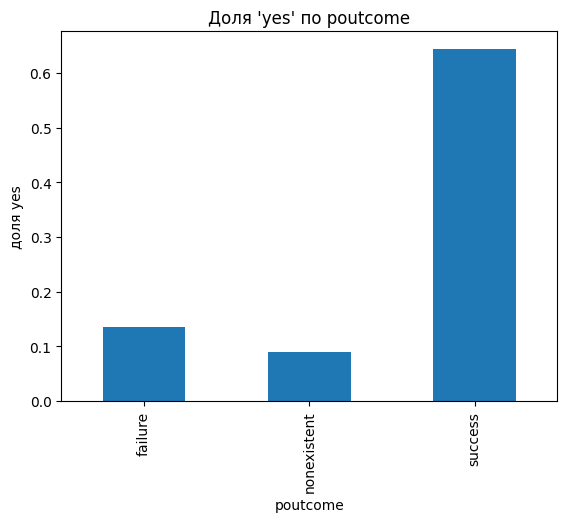

                 mean  count
eur_bin                     
(0.633, 1.299]  0.298   5543
(1.299, 4.191]  0.106   5361
(4.191, 4.864]  0.035   5354
(4.864, 4.962]  0.058   5536
(4.962, 5.045]  0.053   4558


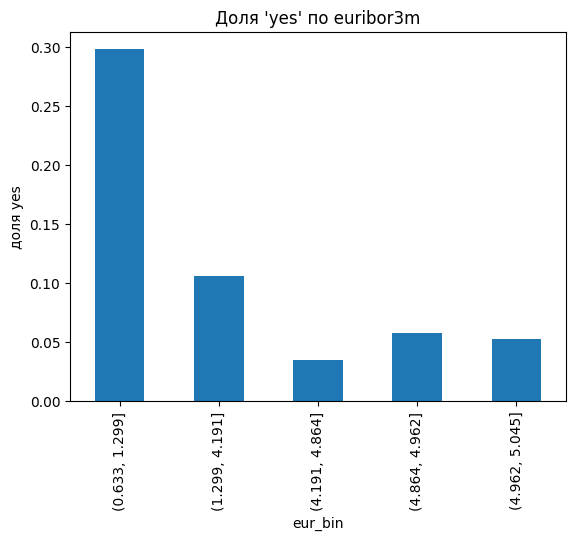

In [12]:
import matplotlib.pyplot as plt

dev = X_dev.assign(y=y_dev)

# График 1: доля "yes" по poutcome
r1 = dev.groupby("poutcome")["y"].agg(["mean", "count"]).round(3)
print(r1)
r1["mean"].plot.bar(title="Доля 'yes' по poutcome")
plt.ylabel("доля yes"); plt.show()

# График 2: доля "yes" по euribor3m (5 равных по размеру групп)
dev["eur_bin"] = pd.qcut(dev["euribor3m"], 5, duplicates="drop")
r2 = dev.groupby("eur_bin", observed=True)["y"].agg(["mean", "count"]).round(3)
print(r2)
r2["mean"].plot.bar(title="Доля 'yes' по euribor3m")
plt.ylabel("доля yes"); plt.show()

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from features import pdays_features

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cat_cols = X_dev.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X_dev.columns if c not in cat_cols] + ["pdays_never"]

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

def make_pipe(model):
    return Pipeline([
        ("pdays", FunctionTransformer(pdays_features, validate=False)),
        ("prep", prep),
        ("model", model),
    ])

def evaluate(name, model):
    res = cross_validate(make_pipe(model), X_dev, y_dev, cv=cv,
                         scoring=["roc_auc", "average_precision", "accuracy"])
    for m in ["roc_auc", "average_precision", "accuracy"]:
        s = res[f"test_{m}"]
        print(f"{name:10s} {m:18s} {s.mean():.4f} ± {s.std():.4f}")

evaluate("majority", DummyClassifier(strategy="most_frequent"))
evaluate("logreg", LogisticRegression(max_iter=1000))

majority   roc_auc            0.5000 ± 0.0000
majority   average_precision  0.1127 ± 0.0001
majority   accuracy           0.8873 ± 0.0001
logreg     roc_auc            0.7906 ± 0.0124
logreg     average_precision  0.4518 ± 0.0199
logreg     accuracy           0.8997 ± 0.0021


## Baselines

I compared a majority-class baseline and a simple logistic regression on the same 5 stratified folds (mean ± std over folds).

| Model | ROC-AUC | Average precision | Accuracy |
|---|---|---|---|
| Majority class | 0.5000 ± 0.0000 | 0.1127 ± 0.0001 | 0.8873 ± 0.0001 |
| Logistic regression | 0.7906 ± 0.0124 | 0.4518 ± 0.0199 | 0.8997 ± 0.0021 |

Accuracy is misleading here. Only about 11.3% of the clients say "yes", so a model that always answers "no" already gets 0.887 accuracy while finding zero buyers. Logistic regression improves accuracy by only about 0.012, but its average precision is about four times higher than the baseline (0.452 vs 0.113). Because the bank can call only the top 10% of clients, I care about how well the model ranks clients, so I use ROC-AUC and average precision instead of accuracy.

These results are the bar for every later model. A candidate must beat ROC-AUC 0.79 and average precision 0.45. The fold-to-fold standard deviation of ROC-AUC is about 0.012, so a difference smaller than that is within the noise, and I will not call a winner on it.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

models = {
    "logreg":     LogisticRegression(max_iter=1000),
    "logreg_bal": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "tree":       DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "forest":     RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                         n_jobs=-1, random_state=SEED),
    "forest_bal": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                         class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=SEED),
}

results = {}
for name, m in models.items():
    r = cross_validate(make_pipe(m), X_dev, y_dev, cv=cv,
                       scoring=["roc_auc", "average_precision"])
    results[name] = r
    for k in ["roc_auc", "average_precision"]:
        s = r[f"test_{k}"]
        print(f"{name:11s} {k:18s} {s.mean():.4f} ± {s.std():.4f}")

print("\nROC-AUC difference vs logreg, per fold:")
base = results["logreg"]["test_roc_auc"]
for name, r in results.items():
    d = r["test_roc_auc"] - base
    print(f"{name:11s} {d.round(4)}  mean {d.mean():+.4f}")

logreg      roc_auc            0.7906 ± 0.0124
logreg      average_precision  0.4518 ± 0.0199
logreg_bal  roc_auc            0.7909 ± 0.0117
logreg_bal  average_precision  0.4466 ± 0.0197
tree        roc_auc            0.7701 ± 0.0134
tree        average_precision  0.4136 ± 0.0170
forest      roc_auc            0.7908 ± 0.0126
forest      average_precision  0.4699 ± 0.0178
forest_bal  roc_auc            0.7909 ± 0.0128
forest_bal  average_precision  0.4689 ± 0.0191

ROC-AUC difference vs logreg, per fold:
logreg      [0. 0. 0. 0. 0.]  mean +0.0000
logreg_bal  [-0.0001  0.0027  0.0003 -0.0012 -0.0003]  mean +0.0003
tree        [-0.0183 -0.0224 -0.0178 -0.016  -0.0282]  mean -0.0205
forest      [ 0.003  -0.0041  0.0001 -0.0003  0.002 ]  mean +0.0001
forest_bal  [ 0.005  -0.0081  0.0019 -0.0012  0.0036]  mean +0.0002


In [16]:
import numpy as np
from sklearn.impute import SimpleImputer

def unknown_to_nan(X):
    return X.replace("unknown", np.nan)

prep_alt = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

pipe_alt = Pipeline([
    ("pdays", FunctionTransformer(pdays_features, validate=False)),
    ("unk", FunctionTransformer(unknown_to_nan, validate=False)),
    ("prep", prep_alt),
    ("model", LogisticRegression(max_iter=1000)),
])

a = results["logreg"]["test_roc_auc"]
b = cross_validate(pipe_alt, X_dev, y_dev, cv=cv, scoring="roc_auc")["test_score"]
print("unknown as category:", a.mean().round(4), "±", a.std().round(4))
print("unknown -> mode    :", b.mean().round(4), "±", b.std().round(4))
print("per-fold diff      :", (a - b).round(4))

unknown as category: 0.7906 ± 0.0124
unknown -> mode    : 0.7905 ± 0.0124
per-fold diff      : [ 0.0012 -0.0008  0.0002  0.0008 -0.0008]


In [17]:
base_ap = results["logreg"]["test_average_precision"]
for name, r in results.items():
    d = r["test_average_precision"] - base_ap
    print(f"{name:11s} {d.round(4)}  mean {d.mean():+.4f}")

logreg      [0. 0. 0. 0. 0.]  mean +0.0000
logreg_bal  [-0.0092 -0.0002 -0.0056 -0.0048 -0.0061]  mean -0.0052
tree        [-0.0396 -0.0261 -0.0435 -0.0374 -0.0444]  mean -0.0382
forest      [0.0321 0.0146 0.0153 0.0195 0.0089]  mean +0.0181
forest_bal  [0.0343 0.0102 0.0148 0.0209 0.0049]  mean +0.0170


In [18]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

space_lr = {"model__C": loguniform(1e-3, 1e1)}
rs_lr = RandomizedSearchCV(make_pipe(LogisticRegression(max_iter=2000)), space_lr,
                           n_iter=10, scoring="average_precision", cv=cv,
                           random_state=SEED, n_jobs=-1)
rs_lr.fit(X_dev, y_dev)
print("logreg best:", rs_lr.best_params_, round(rs_lr.best_score_, 4))

logreg best: {'model__C': np.float64(6.126120326574965)} 0.4518
